In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("aqi_prediction_dataset.csv")
df.head()

,name,agency,lat,lon,time,aqi,main_pollutant,pm2_5,pm10,no2,so2,co,o3,dust,temperature,humidity,wind_speed,rain,cams_cell
0,Jigani Industrial Area (Bengaluru Rural),KSPCB,12.781736,77.629897,2022-08-01T00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.2,99,4.8,5.4,12.8_77.6
1,Jigani Industrial Area (Bengaluru Rural),KSPCB,12.781736,77.629897,2022-08-01T01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.3,98,3.6,1.9,12.8_77.6
2,Jigani Industrial Area (Bengaluru Rural),KSPCB,12.781736,77.629897,2022-08-01T02:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.3,98,3.9,0.3,12.8_77.6
3,Jigani Industrial Area (Bengaluru Rural),KSPCB,12.781736,77.629897,2022-08-01T03:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.3,98,8.9,0.2,12.8_77.6
4,Jigani Industrial Area (Bengaluru Rural),KSPCB,12.781736,77.629897,2022-08-01T04:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.2,98,8.8,0.1,12.8_77.6


In [3]:
df.shape

(475995, 19)

In [4]:
df.columns

Index(['name', 'agency', 'lat', 'lon', 'time', 'aqi', 'main_pollutant',
       'pm2_5', 'pm10', 'no2', 'so2', 'co', 'o3', 'dust', 'temperature',
       'humidity', 'wind_speed', 'rain', 'cams_cell'],
      dtype='str')

In [5]:
df.isnull().sum()

name                 0
agency               0
lat                  0
lon                  0
time                 0
aqi               1222
main_pollutant    1222
pm2_5             1001
pm10              1001
no2               1001
so2               1001
co                1001
o3                1001
dust              1001
temperature          0
humidity             0
wind_speed           0
rain                 0
cams_cell            0
dtype: int64

In [6]:
pollutants = ['pm2_5', 'pm10', 'no2', 'so2', 'co', 'so2', 'o3']

df = df.dropna(subset=['aqi']).copy()
df.isnull().sum()

name              0
agency            0
lat               0
lon               0
time              0
aqi               0
main_pollutant    0
pm2_5             0
pm10              0
no2               0
so2               0
co                0
o3                0
dust              0
temperature       0
humidity          0
wind_speed        0
rain              0
cams_cell         0
dtype: int64

In [7]:
df.head()

,name,agency,lat,lon,time,aqi,main_pollutant,pm2_5,pm10,no2,so2,co,o3,dust,temperature,humidity,wind_speed,rain,cams_cell
94,Jigani Industrial Area (Bengaluru Rural),KSPCB,12.781736,77.629897,2022-08-04T22:00,38.0,O3,5.8,8.4,17.5,3.1,250.0,31.0,0.0,20.2,98,15.8,1.9,12.8_77.6
95,Jigani Industrial Area (Bengaluru Rural),KSPCB,12.781736,77.629897,2022-08-04T23:00,34.0,O3,3.8,5.4,12.0,2.8,205.0,35.0,0.0,20.1,98,18.4,2.1,12.8_77.6
96,Jigani Industrial Area (Bengaluru Rural),KSPCB,12.781736,77.629897,2022-08-05T00:00,32.0,O3,2.5,3.6,8.9,2.5,180.0,38.0,0.0,20.1,97,21.2,1.9,12.8_77.6
97,Jigani Industrial Area (Bengaluru Rural),KSPCB,12.781736,77.629897,2022-08-05T01:00,33.0,O3,2.2,3.1,6.4,2.2,158.0,42.0,0.0,20.0,97,22.4,1.6,12.8_77.6
98,Jigani Industrial Area (Bengaluru Rural),KSPCB,12.781736,77.629897,2022-08-05T02:00,35.0,O3,2.0,2.9,3.9,1.8,136.0,46.0,0.0,19.8,97,22.3,2.2,12.8_77.6


In [8]:
df.describe()

,lat,lon,aqi,pm2_5,pm10,no2,so2,co,o3,dust,temperature,humidity,wind_speed,rain
count,474773.000000,474773.000000,474773.000000,474773.000000,474773.000000,474773.000000,474773.000000,474773.000000,474773.000000,474773.000000,474773.000000,474773.000000,474773.000000,474773.000000
mean,12.947078,77.578071,75.385751,20.530939,28.044016,14.808431,7.348448,362.050904,71.632709,5.013577,23.586653,69.329669,11.810104,0.111590
std,0.062055,0.046625,38.773809,14.287565,18.406051,14.680518,5.124615,219.261046,39.009731,9.202030,4.219854,22.682867,5.157307,0.545504
min,12.781736,77.494094,17.000000,0.400000,0.600000,0.000000,0.300000,59.000000,0.000000,0.000000,10.500000,9.000000,0.000000,0.000000
25%,12.920984,77.544655,46.000000,8.700000,13.200000,5.600000,3.700000,224.000000,40.000000,0.000000,20.500000,54.000000,8.200000,0.000000
50%,12.938539,77.585901,68.000000,17.900000,25.100000,10.400000,5.900000,312.000000,65.000000,1.000000,22.900000,73.000000,11.400000,0.000000
75%,12.990083,77.595080,94.000000,29.200000,39.500000,18.400000,9.600000,430.000000,94.000000,6.000000,26.400000,90.000000,14.800000,0.000000
max,13.029152,77.664561,301.000000,111.300000,141.100000,149.300000,55.700000,4146.000000,232.000000,117.000000,40.000000,100.000000,40.000000,20.600000


In [9]:
x = df.drop(columns=['name', 'agency', 'lat', 'lon', 'time', 'aqi', 'main_pollutant', 'cams_cell'])
y = df['aqi']
features = ['pm2_5', 'pm10', 'no2', 'so2', 'co', 'o3', 'dust', 'temperature', 'humidity', 'wind_speed', 'rain']

In [10]:
x.head()

,pm2_5,pm10,no2,so2,co,o3,dust,temperature,humidity,wind_speed,rain
94,5.8,8.4,17.5,3.1,250.0,31.0,0.0,20.2,98,15.8,1.9
95,3.8,5.4,12.0,2.8,205.0,35.0,0.0,20.1,98,18.4,2.1
96,2.5,3.6,8.9,2.5,180.0,38.0,0.0,20.1,97,21.2,1.9
97,2.2,3.1,6.4,2.2,158.0,42.0,0.0,20.0,97,22.4,1.6
98,2.0,2.9,3.9,1.8,136.0,46.0,0.0,19.8,97,22.3,2.2


In [11]:
print(f"X Shape:{x.shape}")
print(f"Y Shape:{y.shape}")

X Shape:(474773, 11)
Y Shape:(474773,)


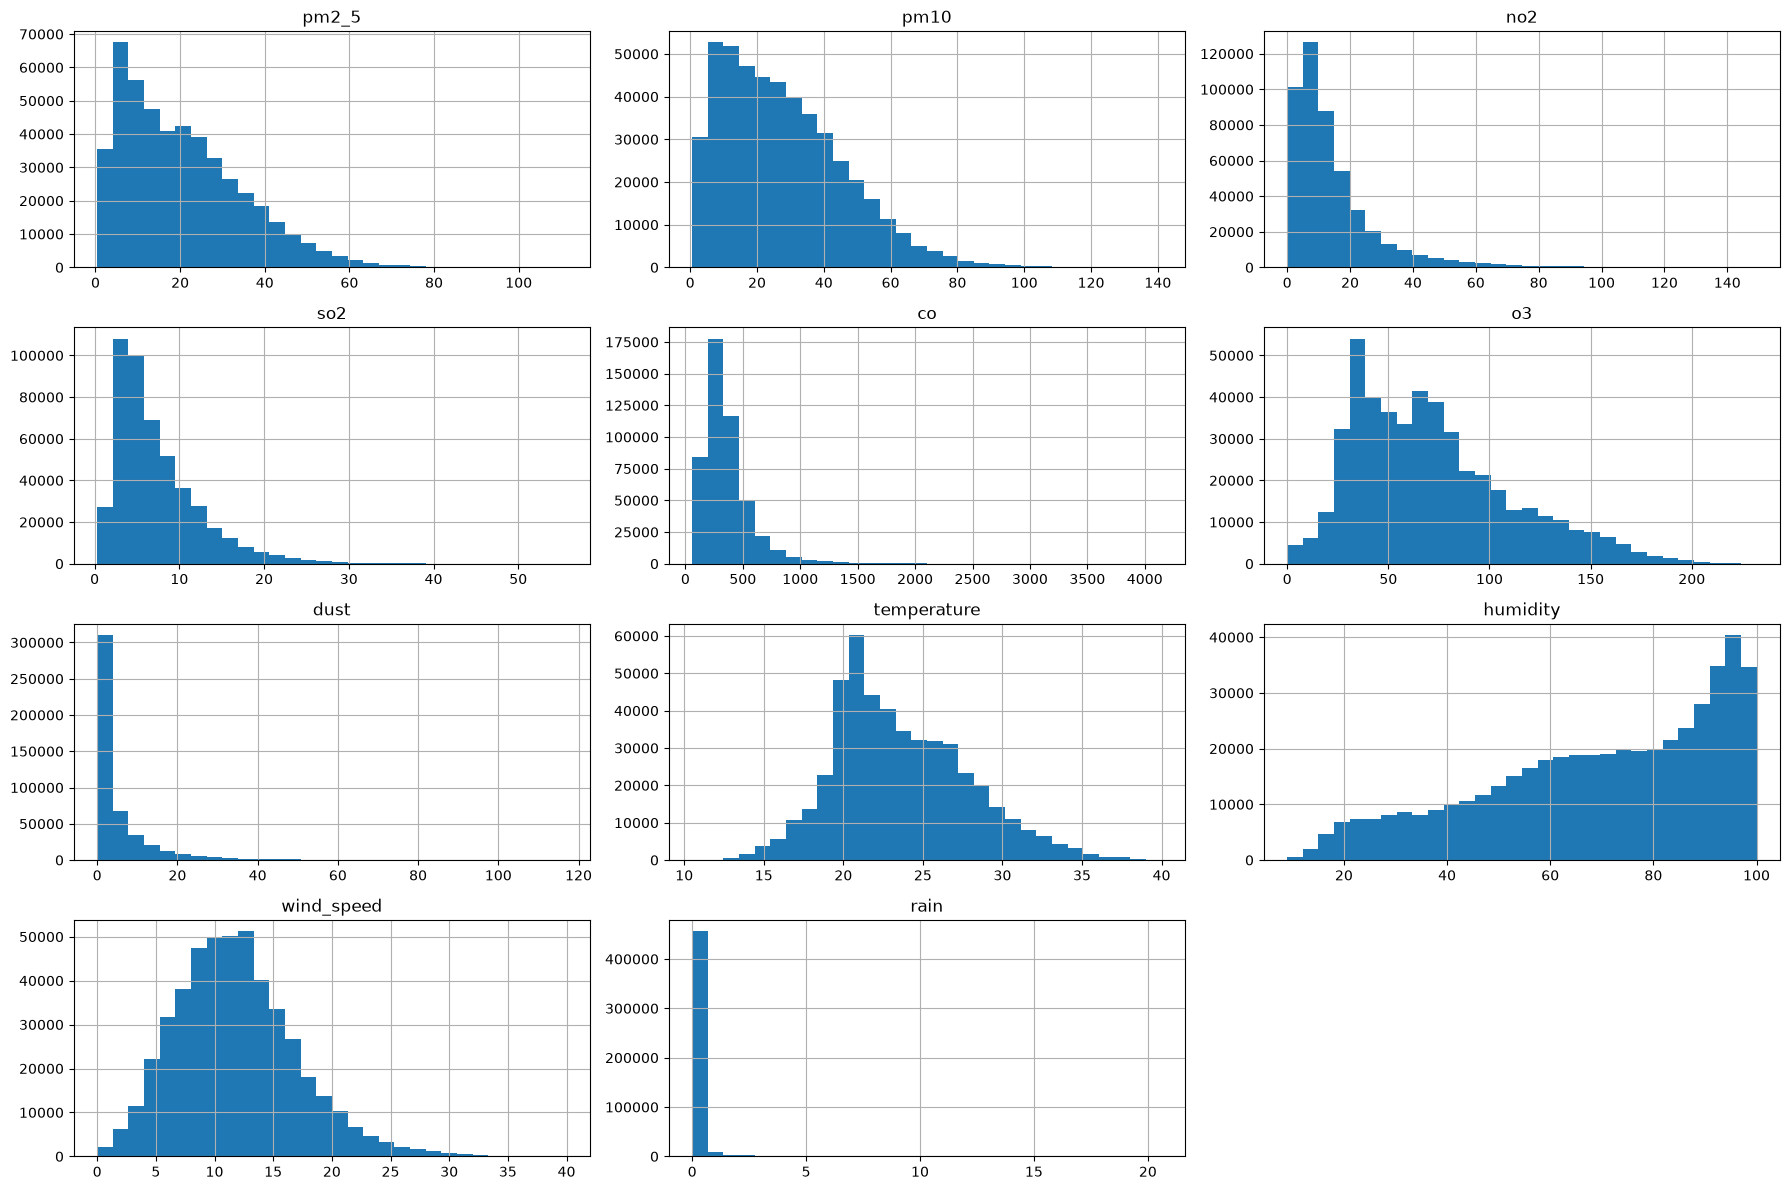

In [12]:
df[features].hist(figsize=(18, 12), bins=30)

plt.tight_layout()
plt.show()

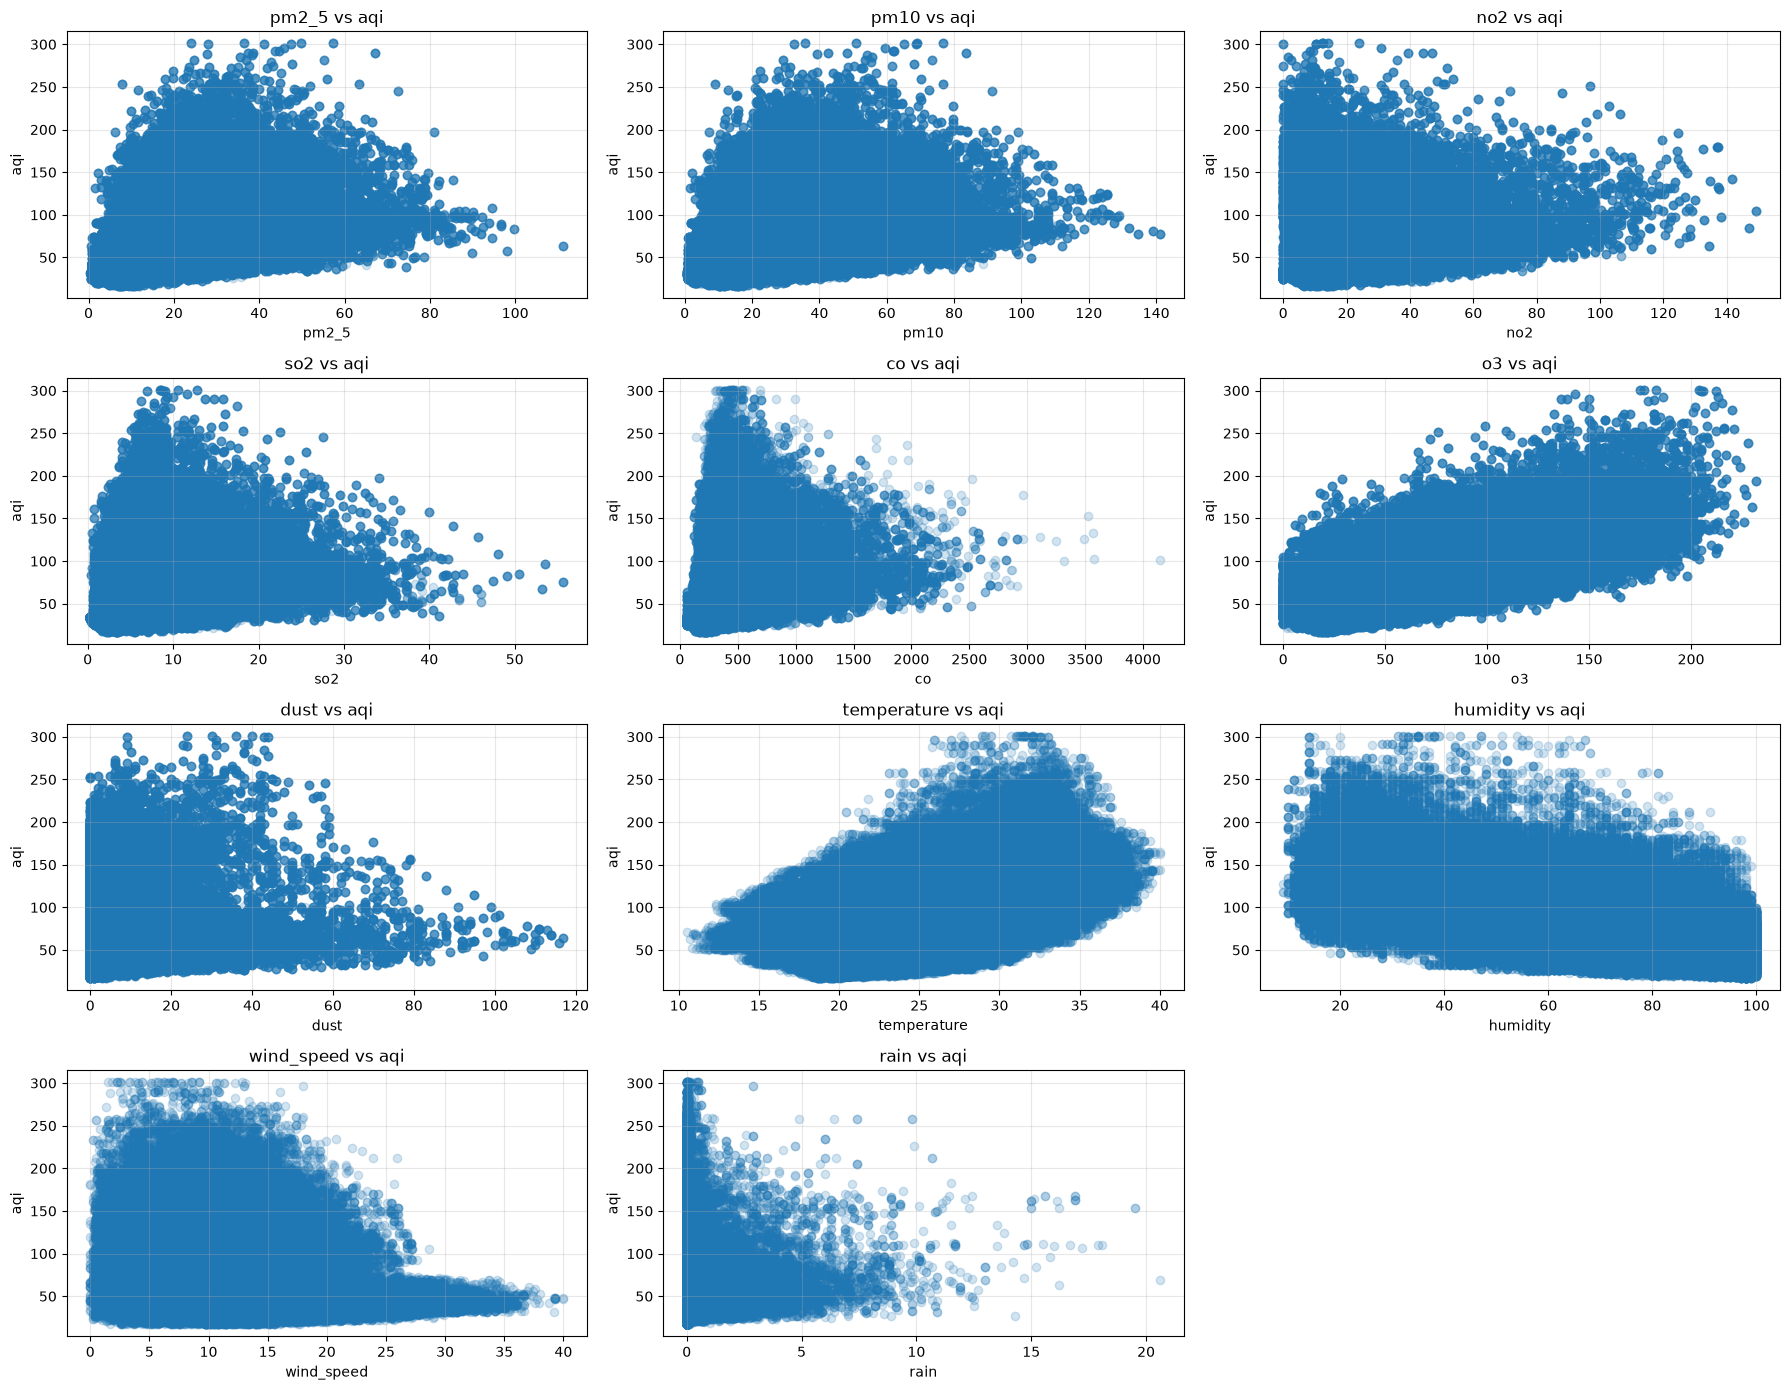

In [14]:
fig, axes = plt.subplots(4, 3, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(features):
    axes[i].scatter(df[col], df['aqi'], alpha=0.2)
    axes[i].set_title(f'{col} vs aqi')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('aqi')
    axes[i].grid(True, alpha=0.3)

for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [13]:
x_train1,x_test1,y_train1,y_test1 = train_test_split(x,y,train_size=0.8,random_state=42)

scaler = MinMaxScaler()
x_train_scaled1 = scaler.fit_transform(x_train1)
x_test_scaled1 = scaler.transform(x_test1)

print(f"x_train Shape:{x_train_scaled1.shape}")
print(f"x_test Shape:{x_test_scaled1.shape}")
print(f"y_train Shape:{y_train1.shape}")
print(f"y_test Shape:{y_test1.shape}")

x_train Shape:(379818, 11)
x_test Shape:(94955, 11)
y_train Shape:(379818,)
y_test Shape:(94955,)


In [14]:
lr = LinearRegression()

lr = lr.fit(x_train_scaled1,y_train1)
y_pred1_train = lr.predict(x_train_scaled1)
y_pred1 = lr.predict(x_test_scaled1)

print(f" Coefficient: {lr.coef_}\n")
print(f" Intercept: {lr.intercept_}")

 Coefficient: [ 42.151597   -39.80962604 202.89673706 -42.15656458   5.72842659
 207.35967604   4.1565319  -41.5837193  -32.45171767  13.82185375
  25.0995801 ]

 Intercept: 31.878805584748292


Training data Performance

In [15]:
print(f"Mean Absolute Error: {mean_absolute_error(y_train1,y_pred1_train)}")
print(f"Mean Squared Error: {mean_squared_error(y_train1,y_pred1_train)}")
print(f"R2 Score: {r2_score(y_train1,y_pred1_train)}")

Mean Absolute Error: 13.509622164627249
Mean Squared Error: 355.94136990900824
R2 Score: 0.7636543167266184


Testing data Performance

In [17]:
print(f"Mean Absolute Error: {mean_absolute_error(y_test1,y_pred1)}")
print(f"Mean Squared Error: {mean_squared_error(y_test1,y_pred1)}")
print(f"R2 Score: {r2_score(y_test1,y_pred1)}")

Mean Absolute Error: 13.428151910711792
Mean Squared Error: 350.9389490417848
R2 Score: 0.7649308012028653


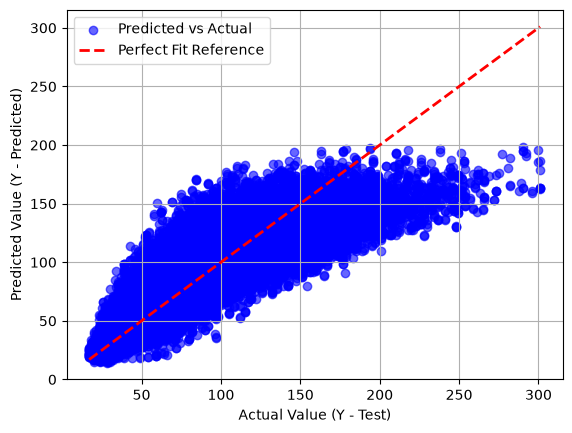

In [18]:
plt.scatter(y_test1, y_pred1, color='blue', alpha=0.6, label='Predicted vs Actual')

ideal_line = [min(y_test1), max(y_test1)]
plt.plot(ideal_line, ideal_line, color='red', linestyle='--', linewidth=2, label='Perfect Fit Reference')
plt.xlabel('Actual Value (Y - Test)')
plt.ylabel('Predicted Value (Y - Predicted)')
plt.legend()
plt.grid(True)

plt.show()

In [17]:
poly = PolynomialFeatures(degree=2)

x_train2, x_test2, y_train2, y_test2 = train_test_split(x,y, train_size=0.8, random_state=42)

x_train_scaled2 = scaler.fit_transform(x_train2)
x_test_scaled2 = scaler.transform(x_test2)

x_train_poly2 = poly.fit_transform(x_train_scaled2)
x_test_poly2 = poly.transform(x_test_scaled2)

lr2 = LinearRegression()
lr2.fit(x_train_poly2,y_train2)

y_pred2_train = lr2.predict(x_train_poly2)
y_pred2 = lr2.predict(x_test_poly2)

print(f" Coefficient: {lr2.coef_}\n")
print(f" Intercept: {lr2.intercept_}")

 Coefficient: [-3.21854417e-14 -2.24794770e+02  3.33933366e+02 -1.86521516e+02
  4.84217169e+01 -1.00676194e+02  3.09160553e+00 -2.22494920e+02
 -3.73793733e+01 -7.83731904e+01 -5.65870835e+01  5.44951096e+01
  7.02114362e+02 -1.39055788e+03 -3.00563281e+02 -1.53533267e+01
  2.44940240e+02 -2.84480394e+01  5.96626810e+02  4.50896613e+02
  8.22351604e+01  1.82991425e+02 -1.08608131e+01  7.01257687e+02
  9.18739623e+01  1.20355852e+02 -2.10593381e+02 -9.79716010e+01
 -5.86690701e+02 -4.22542228e+02 -1.60654852e+02 -2.72014989e+02
  1.58559204e+02  3.40147207e+01 -1.04900112e+02  1.00972801e+02
  9.08145305e+02  3.08407846e+02  4.75183073e+02  3.31250325e+01
  6.36758634e+01 -1.34346948e+01  1.46348368e+02 -3.24035501e+02
 -3.07795704e+02 -5.25253486e+02 -1.94535141e+02  1.71483461e+01
  1.88618811e+02 -1.03334747e+02  1.58644495e+02 -4.66553494e+01
  8.69690698e+01  1.01368882e+02  1.20408888e+02 -7.67729253e+01
  1.39217405e+02  1.64905491e+02  1.55599519e+02  4.50731666e+01
  3.0717079

Training data Performance

In [18]:
print(f"Mean Absolute Error: {mean_absolute_error(y_train2,y_pred2_train)}")
print(f"Mean Squared Error: {mean_squared_error(y_train2,y_pred2_train)}")
print(f"R2 Score: {r2_score(y_train2,y_pred2_train)}")

Mean Absolute Error: 10.80530128643315
Mean Squared Error: 234.65229535736705
R2 Score: 0.8441904713349795


Testing data Performance

In [20]:
print(f"Mean Absolute Error: {mean_absolute_error(y_test2,y_pred2)}")
print(f"Mean Squared Error: {mean_squared_error(y_test2,y_pred2)}")
print(f"R2 Score: {r2_score(y_test2,y_pred2)}")

Mean Absolute Error: 10.800142240501883
Mean Squared Error: 234.16241521447367
R2 Score: 0.8431511478473299


In [19]:
poly = PolynomialFeatures(degree=3)

x_train3, x_test3, y_train3, y_test3 = train_test_split(x, y, train_size=0.8, random_state=42)

x_train_scaled3 = scaler.fit_transform(x_train3)
x_test_scaled3 = scaler.transform(x_test3)

x_train_poly3 = poly.fit_transform(x_train_scaled3)
x_test_poly3 = poly.transform(x_test_scaled3)

lr3 = LinearRegression()
lr3.fit(x_train_poly3,y_train3)

y_pred3_train = lr3.predict(x_train_poly3)
y_pred3 = lr3.predict(x_test_poly3)

print(f" Coefficient: {lr3.coef_}\n")
print(f" Intercept: {lr3.intercept_}")

 Coefficient: [-2.31948976e-12 -1.13259679e+03  1.49480386e+03 -3.81071426e+02
  2.63398534e+02 -1.56288676e+01 -1.65389558e+02 -3.10096998e+03
 -3.00989923e+02 -4.72780526e+01  7.59474959e+01  5.31620973e+03
  3.08886109e+02  6.76165676e+02 -3.71330343e+02 -1.88351599e+03
  1.54978386e+03 -9.17456717e+02  7.97753868e+02  3.38991055e+03
  2.17762838e+03 -4.27784863e+02 -3.04153780e+03 -7.52860786e+02
  9.50771293e+01  1.16112987e+03 -1.60215147e+03 -3.83598809e+02
 -2.82514963e+03 -2.42357210e+03 -2.41605371e+03 -3.25217967e+02
  4.72444681e+03  6.03632530e+02 -7.04616652e+01 -1.03508123e+03
  7.29826168e+02 -8.99128159e+02  7.58824264e+02 -3.13053163e+02
  1.17714830e+03 -3.97468405e+03  6.55124686e+01  1.07538727e+03
  4.88187279e+02  3.22769249e+03 -1.42269577e+03 -9.43864011e+01
 -3.09764993e+02  2.51749827e+03  4.06339484e+01 -6.80019613e+02
  2.36132421e+02  6.43370536e+01  3.77271157e+02 -8.81395651e+02
  1.37872068e+03  5.95978613e+02  1.33389638e+03  7.02969229e+01
  9.7271135

Training Data Performance

In [20]:
print(f"Mean Absolute Error: {mean_absolute_error(y_train3,y_pred3_train)}")
print(f"Mean Squared Error: {mean_squared_error(y_train3,y_pred3_train)}")
print(f"R2 Score: {r2_score(y_train3,y_pred3_train)}")

Mean Absolute Error: 9.664055140563109
Mean Squared Error: 190.16698655011334
R2 Score: 0.873728793077028


Testing Data Performance

In [21]:
print(f"Mean Absolute Error: {mean_absolute_error(y_test3,y_pred3)}")
print(f"Mean Squared Error: {mean_squared_error(y_test3,y_pred3)}")
print(f"R2 Score: {r2_score(y_test3,y_pred3)}")

Mean Absolute Error: 9.669960610297144
Mean Squared Error: 190.32921879145601
R2 Score: 0.8725119081505397


In [22]:
poly = PolynomialFeatures(degree=4)

x_train4, x_test4, y_train4, y_test4 = train_test_split(x, y, train_size=0.8, random_state=42)

x_train_scaled4 = scaler.fit_transform(x_train4)
x_test_scaled4 = scaler.transform(x_test4)

x_train_poly4 = poly.fit_transform(x_train_scaled4)
x_test_poly4 = poly.transform(x_test_scaled4)

lr4 = LinearRegression()
lr4.fit(x_train_poly4,y_train4)

y_pred4_train = lr4.predict(x_train_poly4)
y_pred4 = lr4.predict(x_test_poly4)

print(f" Coefficient: {lr4.coef_}\n")
print(f" Intercept: {lr4.intercept_}")

 Coefficient: [ 1.64734621e-09  3.78935582e+02 -1.28723909e+03 ... -2.12354930e+02
  3.93324134e+01  3.40842943e+02]

 Intercept: -520.6299187142679


Training Data Performance

In [23]:
print(f"Mean Absolute Error: {mean_absolute_error(y_train4,y_pred4_train)}")
print(f"Mean Squared Error: {mean_squared_error(y_train4,y_pred4_train)}")
print(f"R2 Score: {r2_score(y_train4,y_pred4_train)}")

Mean Absolute Error: 8.910312670734623
Mean Squared Error: 162.4460000426647
R2 Score: 0.8921355759098019


Testing Data Performance

In [24]:
print(f"Mean Absolute Error: {mean_absolute_error(y_test4,y_pred4)}")
print(f"Mean Squared Error: {mean_squared_error(y_test4,y_pred4)}")
print(f"R2 Score: {r2_score(y_test4,y_pred4)}")

Mean Absolute Error: 8.922893412750529
Mean Squared Error: 163.20303709501334
R2 Score: 0.8906818200831392


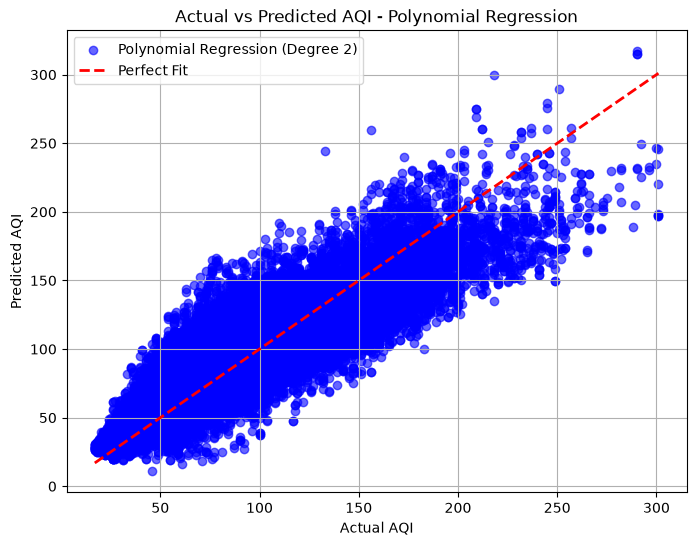

In [25]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test2, y_pred2,
    color='blue', alpha=0.6,
    label='Polynomial Regression (Degree 2)'
)

ideal_line = [min(y_test4), max(y_test4)]
plt.plot(
    ideal_line, ideal_line,
    color='red', linestyle='--',
    linewidth=2, label='Perfect Fit'
)

plt.xlabel('Actual AQI')
plt.ylabel('Predicted AQI')
plt.title('Actual vs Predicted AQI - Polynomial Regression')
plt.legend()
plt.grid(True)
plt.show()

In [26]:
import joblib

model_bundle = {
    "scaler": scaler,
    "poly": poly,
    "model": lr3,
    "best_model": lr4,
    "features": list(x_train2.columns),
    "ranges": {
        col: {
            "min": float(x_train2[col].min()),
            "max": float(x_train2[col].max())
        }
        for col in x_train2.columns
    }
}

joblib.dump(model_bundle, "aqi_model.pkl")

['aqi_model.pkl']